In [1]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

matplotlib.use("pgf")
# matplotlib.use('macOsX')
matplotlib.rcParams.update({
    'axes.formatter.use_locale': True,
    "pgf.texsystem": "pdflatex",
    # 'font.family': 'serif',
    # 'text.usetex': True,
    # 'pgf.rcfonts': False,
})
%matplotlib inline

sns.set_style('white')
sns.set_context("paper", font_scale = 1)

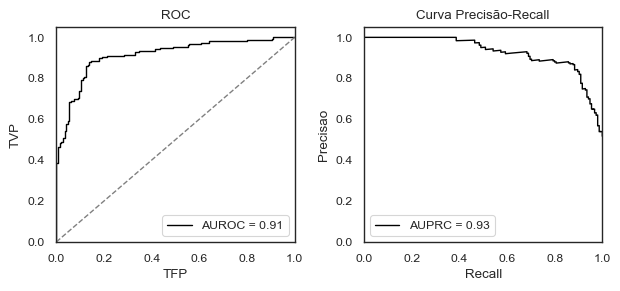

In [3]:
# Generate synthetic binary classification data
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train a logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities for the test set
y_scores = model.predict_proba(X_test)[:, 1]

# Compute ROC curve and ROC area
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

# Compute Precision-Recall curve and PR area
precision, recall, _ = precision_recall_curve(y_test, y_scores)
pr_auc = auc(recall, precision)

# Plot ROC curve
plt.figure(figsize=(6.29707, 3))

plt.subplot(1, 2, 1)
plt.plot(
    fpr,
    tpr,
    color='black',
    lw=1,
    label=f'AUROC = {roc_auc:.2f}'
)
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('TFP')
plt.ylabel('TVP')
plt.title('ROC')
plt.legend(loc="lower right")

# Plot Precision-Recall curve
plt.subplot(1, 2, 2)
plt.plot(
    recall,
    precision,
    color='black',
    lw=1,
    label=f'AUPRC = {pr_auc:.2f}'
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precisao')
plt.title('Curva Precisão-Recall')
plt.legend(loc="lower left")

# Display both plots
plt.tight_layout()
# plt.savefig(
#     f'roc_prcurve_example.pgf',
#     bbox_inches="tight"
# )
plt.savefig(
    f'roc_prcurve_example.png',
    bbox_inches="tight"
)
plt.show()